In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from PIL import Image

In [73]:
train_path = '/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train'
test_path = '/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test'

(150, 150)


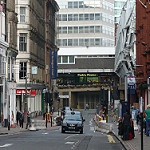

In [74]:
photo = Image.open('/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred/seg_pred/10012.jpg')
print(photo.size)
photo

In [75]:
img_size = (150, 150)
batch_size = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_path, validation_split=0.2, subset="training",
    seed=42, image_size=img_size, batch_size=batch_size)

val_ds = keras.utils.image_dataset_from_directory(
    train_path, validation_split=0.2, subset="validation",
    seed=42, image_size=img_size, batch_size=batch_size)

test_ds = keras.utils.image_dataset_from_directory(
    test_path, image_size=img_size, batch_size=batch_size, shuffle=False)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']




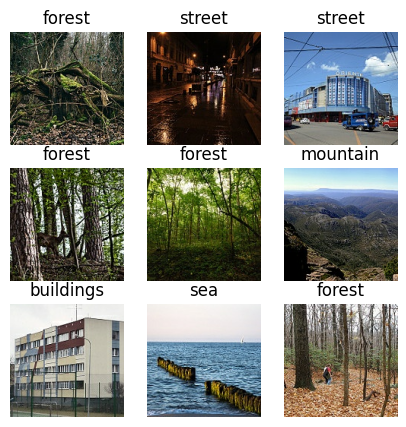

In [76]:
class_names = train_ds.class_names
print("classes:", class_names)
print('\n')

plt.figure(figsize=(5, 5))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [77]:
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)

# CNN

In [80]:
cnn_model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(6, activation="softmax")
])

cnn_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [81]:
cnn_history = cnn_model.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.5387 - loss: 1.1625 - val_accuracy: 0.6575 - val_loss: 0.8904
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.6726 - loss: 0.8645 - val_accuracy: 0.6643 - val_loss: 0.8870
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7424 - loss: 0.7115 - val_accuracy: 0.7591 - val_loss: 0.6433
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7808 - loss: 0.6020 - val_accuracy: 0.7944 - val_loss: 0.5649
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8189 - loss: 0.5191 - val_accuracy: 0.8118 - val_loss: 0.5385
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8450 - loss: 0.4322 - val_accuracy: 0.8108 - val_loss: 0.5878
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8678 - loss: 0.3760 - val_accuracy: 0.8097 - val_loss: 0.6160
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8845 - loss: 0.3231 - val_acc

In [83]:
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds)
print("CNN Test Accuracy:", cnn_test_acc)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8243 - loss: 0.9140
CNN Test Accuracy: 0.8243333101272583


# EfficientNet

In [84]:
base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(150, 150, 3))

base_model.trainable = False

eff_model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax")
])

eff_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

eff_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [85]:
eff_history = eff_model.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15


E0000 00:00:1795538290.922875     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538291.095081     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538294.849090     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538295.025553     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


350/351 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7668 - loss: 0.6491

E0000 00:00:1795538313.841115     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538314.026617     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538314.590675     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538314.745857     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7670 - loss: 0.6484

E0000 00:00:1795538332.096903     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538332.251548     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538333.517573     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538333.698496     262 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


351/351 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.8566 - loss: 0.4062 - val_accuracy: 0.9138 - val_loss: 0.2300
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9114 - loss: 0.2449 - val_accuracy: 0.9244 - val_loss: 0.2077
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9214 - loss: 0.2165 - val_accuracy: 0.9262 - val_loss: 0.2003
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9252 - loss: 0.2034 - val_accuracy: 0.9266 - val_loss: 0.1991
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9289 - loss: 0.1935 - val_accuracy: 0.9266 - val_loss: 0.1958
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9297 - loss: 0.1898 - val_accuracy: 0.9294 - val_loss: 0.1929
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9320 - loss: 0.1848 - val_accuracy: 0.9287 - val_loss: 0.1917
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9324 - loss: 0.1834 - val_accuracy: 0.92

In [86]:
eff_test_loss, eff_test_acc = eff_model.evaluate(test_ds)
print("EfficientNetB0 Test Accuracy:", eff_test_acc)

92/94 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9244 - loss: 0.2199

E0000 00:00:1795538450.296834     264 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538450.452305     264 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538451.348288     264 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795538451.523686     264 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.9243 - loss: 0.2195
EfficientNetB0 Test Accuracy: 0.9243333339691162


# Comparison

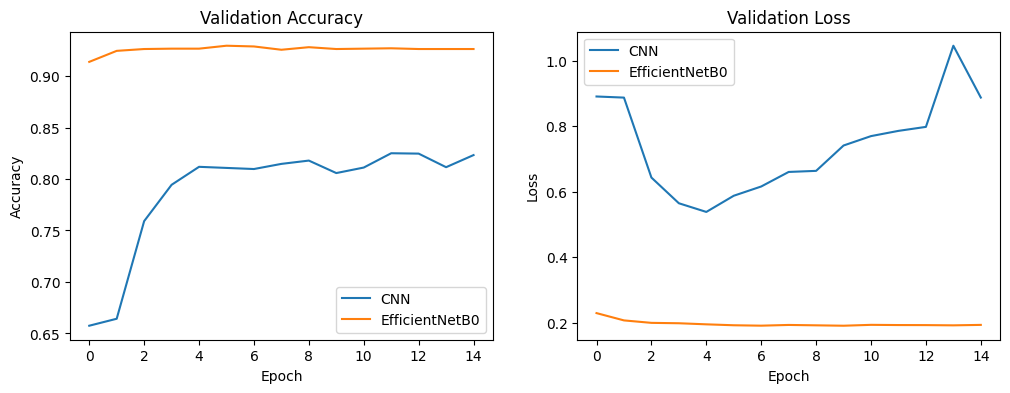

In [87]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["val_accuracy"], label="CNN")
plt.plot(eff_history.history["val_accuracy"], label="EfficientNetB0")
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["val_loss"], label="CNN")
plt.plot(eff_history.history["val_loss"], label="EfficientNetB0")
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

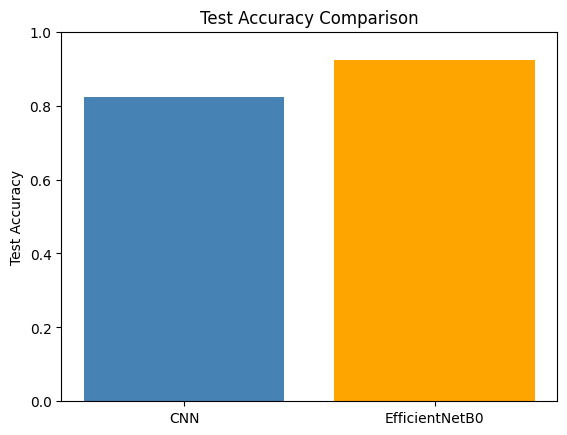

CNN Test Accuracy           : 82.43 %
EfficientNetB0 Test Accuracy: 92.43 %


In [88]:
plt.bar(["CNN", "EfficientNetB0"], [cnn_test_acc, eff_test_acc], color=["steelblue", "orange"])
plt.ylim(0, 1)
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Comparison")
plt.show()

print("CNN Test Accuracy           :", round(cnn_test_acc * 100, 2), "%")
print("EfficientNetB0 Test Accuracy:", round(eff_test_acc * 100, 2), "%")